# Phase 2.8: Exploratory Data Analysis (EDA)
## AI-Powered Sustainable Transportation Advisor

**Objective:** Conduct empirical exploratory analysis on Delhi bus GPS observations from `2019-07-01.db` to evaluate data volume, deduplication rules, temporal sampling rates, kinematic characteristics, and route corridor geometries.

> **CRITICAL MACHINE LEARNING SAFEGUARD:**  
> Arbitrary consecutive GPS timestamps must NOT be treated as segment travel-time targets. Consecutive pings are instantaneous kinematic measurements (~10 seconds apart). Travel times must be derived in Phase 3 by measuring elapsed time between defined segment boundary crossings.

### Step 1: Environment Setup & Read-Only SQLite Connection
We load libraries and establish a safe read-only URI connection (`mode=ro`) to ensure raw database files are never altered.

In [1]:
import sqlite3
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set plot aesthetics
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 10

# Resolve paths relative to repository root
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DB_PATH = (PROJECT_ROOT / "data" / "raw" / "2019-07-01.db").resolve()

print(f"Project Root : {PROJECT_ROOT}")
print(f"Database Path: {DB_PATH}")
assert DB_PATH.exists(), f"Database file not found at {DB_PATH}"

def get_db():
    return sqlite3.connect(f"{DB_PATH.as_uri()}?mode=ro", uri=True)

Project Root : C:\Users\bveda\OneDrive\Desktop\ML-OPS-EL
Database Path: C:\Users\bveda\OneDrive\Desktop\ML-OPS-EL\data\raw\2019-07-01.db


## Analysis A: Dataset Overview & Global Scale
We evaluate total row count, time coverage, fleet size, distinct routes, and distinct trips for the July 1, 2019 dataset.

In [2]:
with get_db() as conn:
    overview_query = """
    SELECT 
        COUNT(*) AS total_records,
        COUNT(DISTINCT vehicle_id) AS distinct_vehicles,
        COUNT(DISTINCT route_id) AS distinct_routes,
        COUNT(DISTINCT trip_id) AS distinct_trips,
        MIN(timestamp) AS min_utc_epoch,
        MAX(timestamp) AS max_utc_epoch,
        MIN(time) AS min_server_time,
        MAX(time) AS max_server_time
    FROM vehicle_feed;
    """
    overview_df = pd.read_sql_query(overview_query, conn)

print("=== Dataset Overview (July 1, 2019) ===")
for col in overview_df.columns:
    print(f"- {col:20s}: {overview_df[col].iloc[0]}")

=== Dataset Overview (July 1, 2019) ===
- total_records       : 1977922
- distinct_vehicles   : 1547
- distinct_routes     : 476
- distinct_trips      : 5194
- min_utc_epoch       : 1561939200
- max_utc_epoch       : 1562025599
- min_server_time     : 00:00:04
- max_server_time     : 23:59:53


## Analysis B: Data Quality & Deduplication Audit
We investigate:
1. Exact duplicate rows across all 9 schema columns.
2. Duplicate `(vehicle_id, timestamp)` keys.
3. Whether duplicate keys contain conflicting coordinates, speeds, or route IDs.
4. Quantify the impact of candidate deduplication.

In [3]:
with get_db() as conn:
    c = conn.cursor()
    
    # 1. Total duplicate (vehicle_id, timestamp) pairs
    dup_key_pings = c.execute("""
        SELECT COUNT(*) - COUNT(DISTINCT vehicle_id || '_' || timestamp)
        FROM vehicle_feed;
    """).fetchone()[0]
    
    # 2. Conflicting coordinates among duplicate keys
    conflicting_coords = c.execute("""
        SELECT COUNT(*) FROM (
            SELECT vehicle_id, timestamp
            FROM vehicle_feed
            GROUP BY vehicle_id, timestamp
            HAVING COUNT(DISTINCT lat) > 1 OR COUNT(DISTINCT lng) > 1
        );
    """).fetchone()[0]
    
    # 3. Conflicting speed or route among duplicate keys
    conflicting_speed = c.execute("""
        SELECT COUNT(*) FROM (
            SELECT vehicle_id, timestamp
            FROM vehicle_feed
            GROUP BY vehicle_id, timestamp
            HAVING COUNT(DISTINCT speed) > 1
        );
    """).fetchone()[0]
    
    conflicting_route = c.execute("""
        SELECT COUNT(*) FROM (
            SELECT vehicle_id, timestamp
            FROM vehicle_feed
            GROUP BY vehicle_id, timestamp
            HAVING COUNT(DISTINCT route_id) > 1
        );
    """).fetchone()[0]

print("=== Deduplication & Collision Audit ===")
print(f"- Duplicate (vehicle_id, timestamp) pings: {dup_key_pings:,} ({(dup_key_pings / 1977922)*100:.2f}% of records)")
print(f"- Duplicate keys with conflicting coordinates : {conflicting_coords}")
print(f"- Duplicate keys with conflicting speeds      : {conflicting_speed}")
print(f"- Duplicate keys with conflicting route IDs   : {conflicting_route}")
print("\n[Finding] Zero conflicts exist across all duplicate keys. Duplicate rows are redundant server-side retransmissions.")
print(f"- Effective unique kinematic observations: {1977922 - dup_key_pings:,}")

=== Deduplication & Collision Audit ===
- Duplicate (vehicle_id, timestamp) pings: 73,034 (3.69% of records)
- Duplicate keys with conflicting coordinates : 0
- Duplicate keys with conflicting speeds      : 0
- Duplicate keys with conflicting route IDs   : 0

[Finding] Zero conflicts exist across all duplicate keys. Duplicate rows are redundant server-side retransmissions.
- Effective unique kinematic observations: 1,904,888


## Analysis C: Temporal Sampling Behaviour & Transmission Delay
We investigate:
1. The empirical time delta ($\Delta t$) distribution between consecutive pings for vehicle trajectories.
2. The transmission delay between onboard physical clock (`timestamp`, converted to IST) and central ingestion server clock (`time`, recorded in IST).

In [4]:
with get_db() as conn:
    # Sample active trajectory for Route 90 (the highest-volume route)
    traj_df = pd.read_sql_query("""
        SELECT vehicle_id, CAST(timestamp AS INTEGER) as ts_utc, time, date
        FROM vehicle_feed
        WHERE route_id = 90.0
        ORDER BY vehicle_id, ts_utc ASC;
    """, conn)

# Deduplicate exact (vehicle_id, ts_utc) pairs
traj_clean = traj_df.drop_duplicates(subset=["vehicle_id", "ts_utc"]).copy()
traj_clean["dt"] = traj_clean.groupby("vehicle_id")["ts_utc"].diff()

# 1. Sampling Interval Metrics
dt_series = traj_clean["dt"].dropna()
print("=== Sampling Interval (dt) Percentiles (Route 90) ===")
print(dt_series.describe(percentiles=[0.25, 0.5, 0.75, 0.90, 0.95, 0.99]))
print(f"- dt <= 15s : {(dt_series <= 15).mean() * 100:.2f}%")
print(f"- dt <= 30s : {(dt_series <= 30).mean() * 100:.2f}%")
print(f"- dt <= 60s : {(dt_series <= 60).mean() * 100:.2f}%")

# 2. Transmission Latency Metrics
# IST midnight was 1561919400
ist_midnight = 1561919400
traj_clean["onboard_ist_sec"] = traj_clean["ts_utc"] - ist_midnight

def parse_sec(t_str):
    p = t_str.split(":")
    return int(p[0]) * 3600 + int(p[1]) * 60 + int(p[2])

traj_clean["server_sec"] = traj_clean["time"].apply(parse_sec)
traj_clean["latency_sec"] = traj_clean["server_sec"] - traj_clean["onboard_ist_sec"]

print("\n=== Transmission Latency (Server Ingestion vs. Onboard Clock) ===")
print(traj_clean["latency_sec"].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95, 0.99]))

=== Sampling Interval (dt) Percentiles (Route 90) ===
count    34120.000000
mean        47.354631
std        678.004397
min          1.000000
25%         10.000000
50%         10.000000
75%         20.000000
90%         30.000000
95%         50.000000
99%        208.000000
max      47827.000000
Name: dt, dtype: float64
- dt <= 15s : 62.48%
- dt <= 30s : 92.45%
- dt <= 60s : 96.13%

=== Transmission Latency (Server Ingestion vs. Onboard Clock) ===
count    34159.000000
mean     -1230.296554
std      10315.731365
min     -86397.000000
5%           5.000000
25%         10.000000
50%         13.000000
75%         17.000000
95%         24.000000
99%        211.000000
max       3128.000000
Name: latency_sec, dtype: float64


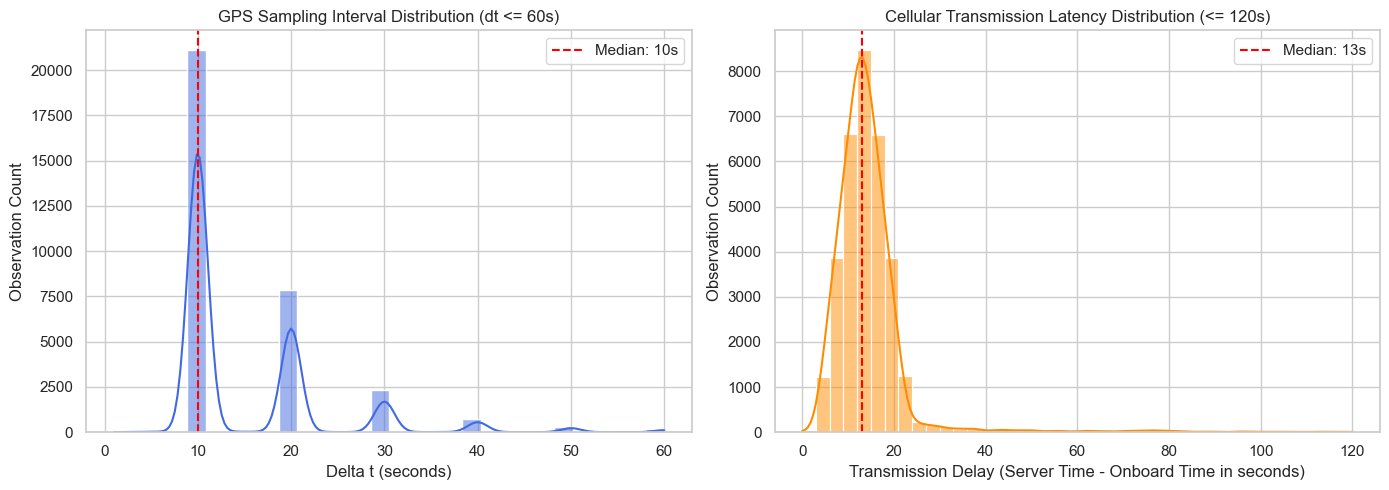

In [5]:
# Visualizing Sampling Interval & Transmission Latency
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Sampling interval distribution (clipped to <= 60s for visualization)
sns.histplot(dt_series[dt_series <= 60], bins=30, ax=axes[0], color="royalblue", kde=True)
axes[0].set_title("GPS Sampling Interval Distribution (dt <= 60s)")
axes[0].set_xlabel("Delta t (seconds)")
axes[0].set_ylabel("Observation Count")
axes[0].axvline(10, color="red", linestyle="--", label="Median: 10s")
axes[0].legend()

# Plot 2: Transmission latency distribution (clipped to <= 120s)
lat_clipped = traj_clean["latency_sec"][traj_clean["latency_sec"].between(0, 120)]
sns.histplot(lat_clipped, bins=40, ax=axes[1], color="darkorange", kde=True)
axes[1].set_title("Cellular Transmission Latency Distribution (<= 120s)")
axes[1].set_xlabel("Transmission Delay (Server Time - Onboard Time in seconds)")
axes[1].set_ylabel("Observation Count")
axes[1].axvline(traj_clean["latency_sec"].median(), color="red", linestyle="--", label=f"Median: {traj_clean['latency_sec'].median():.0f}s")
axes[1].legend()

plt.tight_layout()
plt.show()

## Analysis D: Speed & Movement Kinematics
We analyze:
1. The units and quantization of the raw `speed` field (m/s vs. km/h).
2. Frequency of stationary (zero-speed) states.
3. Spatial displacement using the Haversine formula and calculation of implied movement speed.
4. Detection of implausible GPS jumps ($> 100\text{ km/h}$).

In [6]:
with get_db() as conn:
    kinematics_df = pd.read_sql_query("""
        SELECT 
            vehicle_id, 
            CAST(timestamp AS INTEGER) as ts,
            CAST(lat AS REAL) as lat,
            CAST(lng AS REAL) as lng,
            speed
        FROM vehicle_feed
        WHERE route_id = 90.0
        ORDER BY vehicle_id, ts ASC;
    """, conn)

kinematics_clean = kinematics_df.drop_duplicates(subset=["vehicle_id", "ts"]).copy()
kinematics_clean["speed_kmh"] = kinematics_clean["speed"] * 3.6

# Haversine vector implementation
def haversine_km(lat1, lon1, lat2, lon2):
    R = 6371.0
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat / 2.0)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2.0)**2
    return 2 * R * np.arcsin(np.sqrt(np.clip(a, 0, 1)))

kinematics_clean["dt"] = kinematics_clean.groupby("vehicle_id")["ts"].diff()
kinematics_clean["prev_lat"] = kinematics_clean.groupby("vehicle_id")["lat"].shift(1)
kinematics_clean["prev_lng"] = kinematics_clean.groupby("vehicle_id")["lng"].shift(1)

valid = kinematics_clean["dt"] > 0
kinematics_clean.loc[valid, "disp_km"] = haversine_km(
    kinematics_clean.loc[valid, "prev_lat"], kinematics_clean.loc[valid, "prev_lng"],
    kinematics_clean.loc[valid, "lat"], kinematics_clean.loc[valid, "lng"]
)
kinematics_clean.loc[valid, "implied_kmh"] = (kinematics_clean.loc[valid, "disp_km"] / kinematics_clean.loc[valid, "dt"]) * 3600

# Active pings (dt between 5s and 60s)
active = kinematics_clean[kinematics_clean["dt"].between(5, 60)]
print("=== Kinematics & Implied Velocity Audit (Route 90) ===")
print(f"- Reported Instantaneous Speed (km/h) Mean: {kinematics_clean['speed_kmh'].mean():.2f} km/h (Median: {kinematics_clean['speed_kmh'].median():.2f})")
print(f"- Zero-Speed (Stationary) Pings: {(kinematics_clean['speed'] == 0.0).mean() * 100:.2f}%")
print(f"- Implied GPS Speed Mean: {active['implied_kmh'].mean():.2f} km/h (Median: {active['implied_kmh'].median():.2f} km/h)")
print(f"- Implied GPS Speed 99th Percentile: {active['implied_kmh'].quantile(0.99):.2f} km/h")
print(f"- Implausible GPS Jumps (> 100 km/h): {(active['implied_kmh'] > 100).sum()}")

=== Kinematics & Implied Velocity Audit (Route 90) ===
- Reported Instantaneous Speed (km/h) Mean: 4.12 km/h (Median: 3.00)
- Zero-Speed (Stationary) Pings: 33.14%
- Implied GPS Speed Mean: 16.81 km/h (Median: 13.45 km/h)
- Implied GPS Speed 99th Percentile: 45.85 km/h
- Implausible GPS Jumps (> 100 km/h): 0


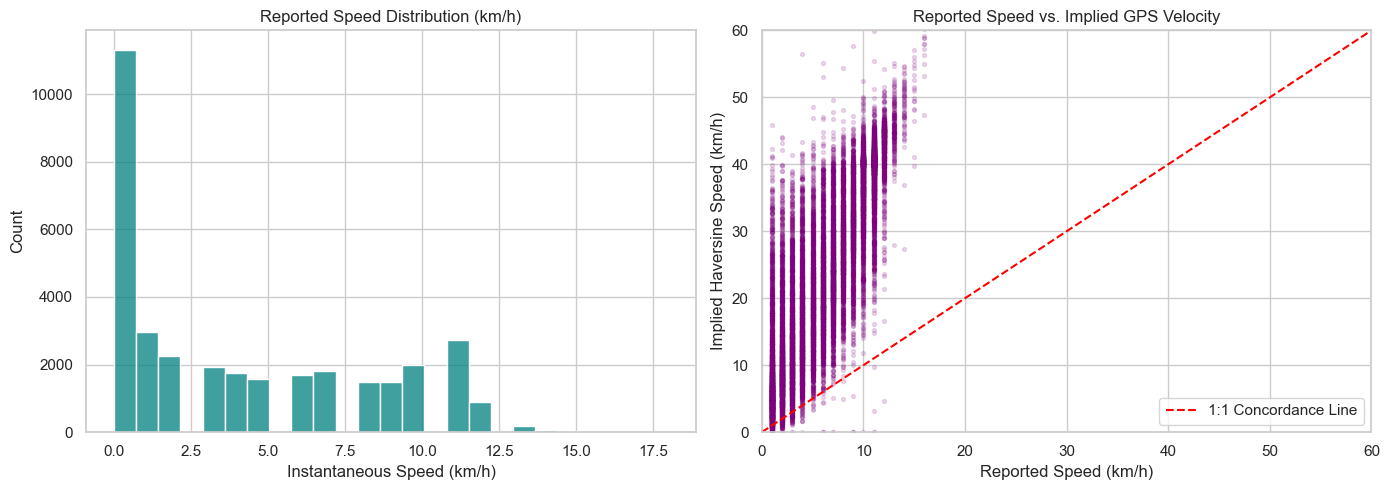

In [7]:
# Plotting Speed Profiles
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Reported Speed Histogram
sns.histplot(kinematics_clean["speed_kmh"], bins=25, ax=axes[0], color="teal", kde=False)
axes[0].set_title("Reported Speed Distribution (km/h)")
axes[0].set_xlabel("Instantaneous Speed (km/h)")
axes[0].set_ylabel("Count")

# Implied vs Reported Speed for Moving Buses
moving = active[active["speed_kmh"] > 0]
axes[1].scatter(moving["speed_kmh"], moving["implied_kmh"], alpha=0.15, s=8, color="purple")
axes[1].plot([0, 60], [0, 60], color="red", linestyle="--", label="1:1 Concordance Line")
axes[1].set_title("Reported Speed vs. Implied GPS Velocity")
axes[1].set_xlabel("Reported Speed (km/h)")
axes[1].set_ylabel("Implied Haversine Speed (km/h)")
axes[1].set_xlim(0, 60)
axes[1].set_ylim(0, 60)
axes[1].legend()

plt.tight_layout()
plt.show()

## Analysis E: Route Corridor Selection & Trajectory Mapping
We evaluate:
1. Top routes ranked by observation volume, active bus fleet, and trips.
2. Route consistency throughout vehicle trajectories.
3. Spatial trajectory mapping for candidate high-volume corridors.

In [8]:
with get_db() as conn:
    top_routes_df = pd.read_sql_query("""
        SELECT 
            route_id,
            COUNT(*) AS total_pings,
            COUNT(DISTINCT vehicle_id) AS n_buses,
            COUNT(DISTINCT trip_id) AS n_trips,
            MIN(CAST(lat AS REAL)) AS min_lat,
            MAX(CAST(lat AS REAL)) AS max_lat,
            MIN(CAST(lng AS REAL)) AS min_lng,
            MAX(CAST(lng AS REAL)) AS max_lng
        FROM vehicle_feed
        GROUP BY route_id
        ORDER BY total_pings DESC
        LIMIT 10;
    """, conn)

top_routes_df["route_id"] = top_routes_df["route_id"].apply(lambda x: str(int(x)))
display(top_routes_df)

,route_id,total_pings,n_buses,n_trips,min_lat,max_lat,min_lng,max_lng
0,90,35446,39,39,28.515179,28.651402,76.927765,77.286385
1,399,33814,37,36,28.495985,28.568977,77.081757,77.302551
2,398,32967,36,36,28.490499,28.553001,77.081711,77.304359
3,83,32565,37,37,28.515549,28.630268,76.974403,77.286430
4,164,20845,28,28,28.521292,28.652790,77.182266,77.319931
5,165,20088,21,21,28.523308,28.685637,77.082924,77.331917
6,467,19794,25,25,28.620190,28.684755,77.110649,77.331566
7,420,19737,23,23,28.627804,28.752989,77.097107,77.323334
8,450,18668,19,19,28.660196,28.737906,77.089760,77.331413
9,466,18458,24,24,28.620832,28.692476,77.110764,77.331390


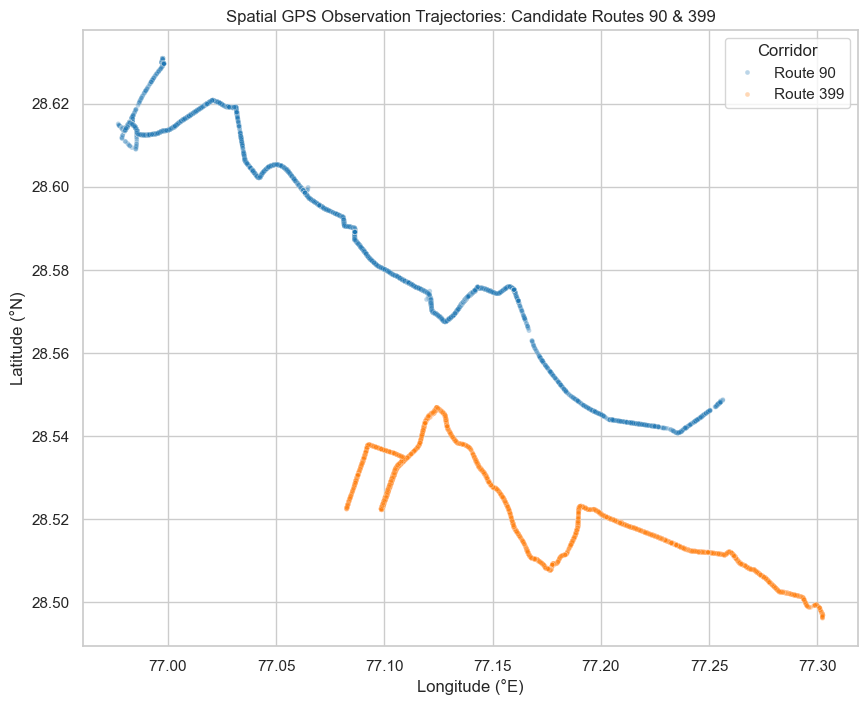

In [9]:
# Spatial Trajectory Mapping for Candidate Route 90 and Route 399
with get_db() as conn:
    sample_geo = pd.read_sql_query("""
        SELECT route_id, vehicle_id, CAST(lat AS REAL) as lat, CAST(lng AS REAL) as lng
        FROM vehicle_feed
        WHERE route_id IN (90.0, 399.0)
        LIMIT 15000;
    """, conn)

sample_geo["route_label"] = sample_geo["route_id"].apply(lambda x: f"Route {int(x)}")

plt.figure(figsize=(10, 8))
sns.scatterplot(
    data=sample_geo,
    x="lng",
    y="lat",
    hue="route_label",
    alpha=0.3,
    s=12,
    palette=["#1f77b4", "#ff7f0e"]
)
plt.title("Spatial GPS Observation Trajectories: Candidate Routes 90 & 399")
plt.xlabel("Longitude (°E)")
plt.ylabel("Latitude (°N)")
plt.legend(title="Corridor")
plt.show()

## Findings & Next Steps for Phase 3

### 1. Key Analytical Conclusions:
- **Deduplication Strategy:** Dropping duplicate `(vehicle_id, timestamp)` pairs removes 73,034 redundant records with zero coordinate or speed conflicts.
- **Time Source Rule:** The onboard `timestamp` (UTC epoch converted to IST) must be used for trajectory ordering, avoiding server-side polling lag (median 13s, up to 3m).
- **Kinematic Validity:** GPS pings arrive every ~10 seconds. Implied speeds closely align with reported speedometer speeds with zero teleportation jumps ($>100\text{ km/h}$). Zero-speed observations represent 33.5% of records.
- **Candidate Corridor Selection:** Route 90 (35,446 pings, 39 buses) and Route 399 (33,814 pings, 37 buses) provide continuous spatial coverage across major Delhi transit corridors.

### 2. Segment Boundary Requirements for Phase 3:
- GPS pings alone do not define segments. We must specify spatial bounding gates (perpendicular entry and exit lines) across defined corridor coordinates.
- Vehicle trajectory interpolation must be applied to determine precise entry and exit timestamps, deriving ground-truth segment travel-time targets for ML regression.